<a href="https://colab.research.google.com/github/Rahardirizky/modul-soil-improvement/blob/main/modul_M4_Asaoka.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# M4 — Prediksi Penurunan Akhir dengan Metode Asaoka

**Tujuan:** memperkirakan penurunan akhir (*ultimate settlement*) dari data monitoring settlement plate menggunakan metode observasional Asaoka (1978).

Alur notebook: **teori → fungsi → contoh penggunaan → visualisasi → unit test → validasi paper**.

> Contoh numerik bersifat ilustratif, bukan data proyek C-2. Data C-2 digunakan sebagai konteks studi kasus; angka yang dibaca dari grafik tidak dianggap sebagai data mentah presisi.

**Pembaruan:** M4 juga memuat verifikasi hasil yang dilaporkan, pemeriksaan surcharge berdasarkan revisi perhitungan terbaru, dan pemeriksaan laju penurunan sisa.

## 1. Dasar teori

Untuk pembacaan settlement pada interval waktu konstan \(\Delta t\), metode Asaoka menyatakan:

\[
S_n = \beta_0 + \beta_1 S_{n-1}
\]

\(S_n\) adalah settlement pada waktu pengamatan ke-\(n\), \(S_{n-1}\) adalah settlement pada waktu sebelumnya, \(\beta_0\) adalah intercept, dan \(\beta_1\) adalah slope regresi.

Pada kondisi akhir, \(S_n=S_{n-1}=S_f\), sehingga:

\[
\boxed{S_f=\frac{\beta_0}{1-\beta_1}}
\]

Derajat konsolidasi berbasis settlement dapat dihitung:

\[
U(t)=\frac{S(t)-S_0}{S_f-S_0}\times100\%
\]

\(S_0\) adalah settlement pada awal periode evaluasi. Jika datum pengukuran dimulai dari nol, \(S_0=0\).

**Syarat dan batasan:** interval waktu harus tetap; rentang data harus mewakili tahap konsolidasi yang cukup berkembang; perubahan tahapan beban dan secondary settlement dapat memengaruhi regresi; \(S_f\) merupakan ekstrapolasi observasional, bukan pengukuran langsung.

## 2. Referensi dan traceability

| Topik | Referensi | Lokasi |
|---|---|---|
| Interval tetap, plot \(S_n\) terhadap \(S_{n-1}\), titik potong | Materi kuliah MPT Minggu 3 | Bagian 3.6, halaman slide 53 |
| Pengaruh \(\Delta t\), secondary settlement, data awal | Presentasi C-2, *Pengalaman Perbaikan Tanah* | Slide 111 |
| Metode observasional Asaoka | Asaoka (1978) | *Soils and Foundations*, 18(4), pp. 87–101 |

**Sumber primer:** Asaoka, A. (1978). *Observational Procedure of Settlement Prediction*. Soils and Foundations, 18(4), 87–101. DOI: https://doi.org/10.3208/sandf1972.18.4_87

Sumber pendukung: Arafianto et al., *Jurnal Teknik Sipil ITB*, bagian 3.2.1, “Interpretasi data hasil pengukuran — Metode Asaoka”: https://journals.itb.ac.id/index.php/jts/article/view/16878/5908

Persamaan \(S_f=\beta_0/(1-\beta_1)\) diperoleh dari kondisi titik potong \(S_n=S_{n-1}\).

## 3. Import library

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 4. Fungsi persiapan data

Memeriksa panjang data, nilai numerik, urutan waktu, dan interval waktu tetap. Rentang analisis dapat dipilih dengan `start_time` dan `end_time`.

In [9]:
def prepare_asaoka_data(time, settlement, start_time=None, end_time=None, interval_tolerance=1e-6):
    """Prepare equally spaced time-settlement observations.

    time: observation time (e.g. days)
    settlement: measured settlement (e.g. mm)
    start_time, end_time: optional inclusive analysis-window limits
    interval_tolerance: absolute tolerance in the time unit
    Returns selected data, constant interval, and consecutive settlement pairs.
    """
    t = np.asarray(time, dtype=float)
    s = np.asarray(settlement, dtype=float)

    if t.ndim != 1 or s.ndim != 1 or len(t) != len(s):
        raise ValueError("time and settlement must be 1D arrays with equal length.")
    if len(t) < 3:
        raise ValueError("At least 3 observations are required.")
    if not np.all(np.isfinite(t)) or not np.all(np.isfinite(s)):
        raise ValueError("time and settlement must contain finite values.")
    if np.any(np.diff(t) <= 0):
        raise ValueError("time must be strictly increasing.")

    mask = np.ones(len(t), dtype=bool)
    if start_time is not None:
        mask &= t >= start_time
    if end_time is not None:
        mask &= t <= end_time
    t_sel, s_sel = t[mask], s[mask]

    if len(t_sel) < 3:
        raise ValueError("Selected window must contain at least 3 observations.")

    intervals = np.diff(t_sel)
    delta_t = float(np.mean(intervals))
    if not np.allclose(intervals, delta_t, rtol=0.0, atol=interval_tolerance):
        raise ValueError("Selected observations must have a constant time interval.")

    return {
        "time": t_sel,
        "settlement": s_sel,
        "delta_t": delta_t,
        "settlement_previous": s_sel[:-1],
        "settlement_current": s_sel[1:],
        "pair_time": t_sel[1:]
    }

## 5. Fungsi analisis Asaoka

Regresi linear menggunakan \(S_{n-1}\) sebagai X dan \(S_n\) sebagai Y. Keluaran meliputi \(\beta_0\), \(\beta_1\), \(R^2\), dan settlement akhir \(S_f\).

In [10]:
def calculate_asaoka_final_settlement(beta0, beta1):
    """Calculate ultimate settlement from reported Asaoka coefficients."""
    beta0, beta1 = float(beta0), float(beta1)
    if not np.isfinite(beta0) or not np.isfinite(beta1):
        raise ValueError("Asaoka coefficients must be finite.")
    if beta0 < 0 or not 0 <= beta1 < 1:
        raise ValueError("Require beta0 >= 0 and 0 <= beta1 < 1.")
    return beta0 / (1.0 - beta1)


In [11]:
def calculate_asaoka(settlement_previous, settlement_current):
    """Fit Sn = beta0 + beta1*Sn-1 and estimate final settlement.

    Inputs: consecutive settlement pairs in the same length unit.
    Outputs: beta0, beta1, R-squared, and final settlement in that unit.
    """
    x = np.asarray(settlement_previous, dtype=float)
    y = np.asarray(settlement_current, dtype=float)

    if x.ndim != 1 or y.ndim != 1 or len(x) != len(y):
        raise ValueError("Settlement pair arrays must be 1D and have equal length.")
    if len(x) < 2:
        raise ValueError("At least 2 settlement pairs are required.")
    if not np.all(np.isfinite(x)) or not np.all(np.isfinite(y)):
        raise ValueError("Settlement pairs must contain finite values.")
    if np.allclose(x, x[0]):
        raise ValueError("Previous settlement values must not all be identical.")

    beta1, beta0 = np.polyfit(x, y, 1)
    y_fit = beta0 + beta1*x
    ss_res = float(np.sum((y-y_fit)**2))
    ss_tot = float(np.sum((y-np.mean(y))**2))
    r_squared = 1.0 - ss_res/ss_tot if ss_tot > 0 else np.nan

    if beta1 >= 1.0:
        raise ValueError("beta1 must be less than 1 for finite final settlement.")
    final_settlement = calculate_asaoka_final_settlement(beta0, beta1)

    return {"beta0": float(beta0), "beta1": float(beta1),
            "r_squared": float(r_squared), "final_settlement": float(final_settlement)}

## 6. Fungsi derajat konsolidasi

Derajat konsolidasi dihitung relatif terhadap settlement awal pada periode evaluasi. Settlement terukur dan settlement akhir harus menggunakan datum serta satuan yang sama.

In [12]:
def calculate_degree_of_consolidation(settlement, final_settlement, initial_settlement=0.0):
    """Calculate settlement-based degree of consolidation (%).

    settlement, final_settlement, initial_settlement use the same length unit.
    """
    s = np.asarray(settlement, dtype=float)
    sf, s0 = float(final_settlement), float(initial_settlement)
    if not np.all(np.isfinite(s)) or not np.isfinite(sf) or not np.isfinite(s0):
        raise ValueError("Settlement values must be finite.")
    if sf <= s0:
        raise ValueError("final_settlement must exceed initial_settlement.")
    return (s-s0)/(sf-s0)*100.0

## 7. Fungsi terintegrasi

In [13]:
def analyze_asaoka(time, settlement, start_time=None, end_time=None,
                   initial_settlement=None, interval_tolerance=1e-6):
    """Run data preparation, Asaoka regression, and settlement-based U calculation.

    time: monitoring time (e.g. days)
    settlement: measured settlement (e.g. mm)
    start_time/end_time: optional analysis-window limits
    initial_settlement: datum at start of evaluated period; defaults to first selected reading
    """
    prepared = prepare_asaoka_data(
        time, settlement, start_time, end_time, interval_tolerance
    )
    fitted = calculate_asaoka(
        prepared["settlement_previous"], prepared["settlement_current"]
    )
    s0 = (float(prepared["settlement"][0]) if initial_settlement is None
          else float(initial_settlement))
    degree = calculate_degree_of_consolidation(
        prepared["settlement"], fitted["final_settlement"], s0
    )
    return {**prepared, **fitted, "initial_settlement": s0,
            "degree_of_consolidation": degree}

## 8. Contoh penggunaan

Data sintetis berikut menggunakan interval 7 hari. Angka hanya untuk demonstrasi, bukan data C-2.

In [14]:
# Illustrative data only
time_days = [0, 7, 14, 21, 28, 35, 42, 49, 56, 63]
settlement_mm = [0, 100, 180, 250, 310, 360, 400, 430, 452, 468]

result = analyze_asaoka(time_days, settlement_mm)

print(f"Delta t       : {result['delta_t']:.2f} days")
print(f"Beta 0        : {result['beta0']:.4f} mm")
print(f"Beta 1        : {result['beta1']:.4f}")
print(f"R-squared     : {result['r_squared']:.4f}")
print(f"Final settle. : {result['final_settlement']:.2f} mm")
print(f"U at last obs.: {result['degree_of_consolidation'][-1]:.2f} %")

Delta t       : 7.00 days
Beta 0        : 101.2359 mm
Beta 1        : 0.8215
R-squared     : 0.9994
Final settle. : 567.04 mm
U at last obs.: 82.53 %


## 9. Visualisasi

Grafik pertama menunjukkan settlement terhadap waktu. Grafik kedua menunjukkan plot \(S_n\) terhadap \(S_{n-1}\), garis regresi, dan garis 45°. Titik potong kedua garis menunjukkan \(S_f\).

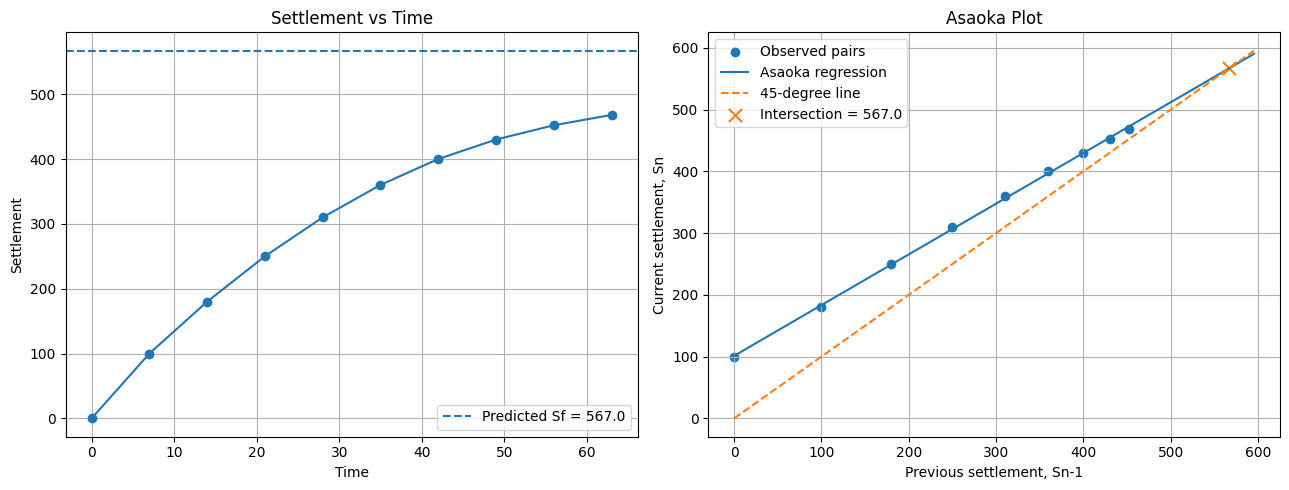

In [15]:
def plot_asaoka(result):
    """Plot time-settlement and Asaoka regression diagrams."""
    t, s = result["time"], result["settlement"]
    x, y = result["settlement_previous"], result["settlement_current"]
    beta0, beta1 = result["beta0"], result["beta1"]
    sf = result["final_settlement"]

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    axes[0].plot(t, s, marker="o")
    axes[0].axhline(sf, linestyle="--", label=f"Predicted Sf = {sf:.1f}")
    axes[0].set_xlabel("Time")
    axes[0].set_ylabel("Settlement")
    axes[0].set_title("Settlement vs Time")
    axes[0].grid(True)
    axes[0].legend()

    upper = max(float(np.max(x)), float(np.max(y)), sf)*1.05
    line = np.linspace(0, upper, 100)
    axes[1].scatter(x, y, label="Observed pairs")
    axes[1].plot(line, beta0+beta1*line, label="Asaoka regression")
    axes[1].plot(line, line, linestyle="--", label="45-degree line")
    axes[1].scatter([sf], [sf], marker="x", s=90, label=f"Intersection = {sf:.1f}")
    axes[1].set_xlabel("Previous settlement, Sn-1")
    axes[1].set_ylabel("Current settlement, Sn")
    axes[1].set_title("Asaoka Plot")
    axes[1].grid(True)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_asaoka(result)

## 10. Tabel hasil

In [16]:
asaoka_pairs = pd.DataFrame({
    "Time (days)": result["pair_time"],
    "S(n-1) (mm)": result["settlement_previous"],
    "S(n) (mm)": result["settlement_current"]
})
display(asaoka_pairs)

summary = pd.DataFrame({
    "Parameter": ["Delta t", "Beta 0", "Beta 1", "R-squared",
                  "Final settlement", "U at last observation"],
    "Value": [result["delta_t"], result["beta0"], result["beta1"],
              result["r_squared"], result["final_settlement"],
              result["degree_of_consolidation"][-1]],
    "Unit": ["days", "mm", "-", "-", "mm", "%"]
})
display(summary)

,Time (days),S(n-1) (mm),S(n) (mm)
0,7.0,0.0,100.0
1,14.0,100.0,180.0
2,21.0,180.0,250.0
3,28.0,250.0,310.0
4,35.0,310.0,360.0
5,42.0,360.0,400.0
6,49.0,400.0,430.0
7,56.0,430.0,452.0
8,63.0,452.0,468.0


,Parameter,Value,Unit
0,Delta t,7.000000,days
1,Beta 0,101.235857,mm
2,Beta 1,0.821465,-
3,R-squared,0.999407,-
4,Final settlement,567.037955,mm
5,U at last observation,82.534158,%


## 11. Verifikasi hasil yang dilaporkan — studi kasus C-2

Bagian ini mengadaptasi hitung ulang manual pada dokumen tugas, Bagian B.3, halaman 6–8. Ini melengkapi regresi Asaoka ketika data monitoring mentah tidak tersedia.

**Penting:** verifikasi hasil yang dilaporkan bukan rekonstruksi regresi Asaoka. Tanpa deret settlement pada interval waktu tetap, \(\beta_0\), \(\beta_1\), dan plot Asaoka tidak dapat dihitung ulang.

Data manual STA 0+100:
- \(S_{150}=1{,}410\) mm; \(S_{final}=1{,}550\) mm; waktu evaluasi 150 hari.
- Sand platform = 3.0 m; top backfill = 0.7 m.
- Berat isi timbunan asumsi = 18 kN/m³.
- Tekanan vakum 80 kPa tercatat pada konteks hitungan manual sebelumnya. Namun, untuk revisi surcharge terbaru yang ditunjukkan pada screenshot, nilai aktual dihitung terpisah dari tinggi surcharge 5 m, yaitu 90 kPa; angka 80 kPa tidak dipakai sebagai pengganti surcharge aktual.
- Asumsi residual settlement = 1 mm/bulan.

### 11.1 Derajat konsolidasi dan settlement tersisa

\[
U=\frac{S_{150}}{S_{final}}\times100\%
=\frac{1410}{1550}\times100\%=90.97\%
\]

\[
S_{remaining}=S_{final}-S_{150}=1550-1410=140\text{ mm}
\]

\[
U_{remaining}=\frac{140}{1550}\times100\%=9.03\%
\]

Kriteria pada dokumen: \(U>90\%\). Hasil 90,97% memenuhi kriteria.

In [17]:
def verify_reported_consolidation(settlement_at_time, final_settlement, target_u=90.0):
    """Verify reported degree of consolidation without raw Asaoka time-series data."""
    s, sf, target = map(float, [settlement_at_time, final_settlement, target_u])
    if not np.all(np.isfinite([s, sf, target])) or s < 0 or sf <= 0:
        raise ValueError("Invalid settlement or target input.")
    degree = s / sf * 100.0
    remaining = sf - s
    return {
        "degree_of_consolidation_percent": degree,
        "remaining_settlement": remaining,
        "remaining_settlement_percent": remaining / sf * 100.0,
        "target_u_percent": target,
        "meets_target": degree > target
    }

c2_consolidation = verify_reported_consolidation(1410, 1550, 90)
print(f"U calculated         : {c2_consolidation['degree_of_consolidation_percent']:.2f}%")
print(f"Remaining settlement : {c2_consolidation['remaining_settlement']:.2f} mm")
print(f"Remaining ratio      : {c2_consolidation['remaining_settlement_percent']:.2f}%")
print(f"Meets U > 90%        : {c2_consolidation['meets_target']}")

U calculated         : 90.97%
Remaining settlement : 140.00 mm
Remaining ratio      : 9.03%
Meets U > 90%        : True


### 11.2 Surcharge terhadap beban akhir

Perhitungan pada bagian ini mengikuti screenshot perhitungan terbaru. Beban akhir dihitung dari tinggi timbunan akhir 3,7 m. Surcharge aktual dihitung terpisah dari tinggi material surcharge 5 m.

**A. Tinggi timbunan akhir**

\[
H=3.0+0.7=3.7\text{ m}
\]

**B. Beban akhir**

Dengan berat isi tanah \(\gamma=18\text{ kN/m}^3\):

\[
q_{final}=\gamma H=18(3.7)=66.6\text{ kPa}
\]

**C. Surcharge minimum**

Kriteria yang digunakan pada perhitungan manual adalah:

\[
q_{surcharge,min}=1.2q_{final}=1.2(66.6)=79.92\text{ kPa}
\]

**D. Surcharge aktual**

Dengan \(\gamma_{surcharge}=18\text{ kN/m}^3\) dan tinggi surcharge \(H_{surcharge}=5\text{ m}\):

\[
q_{surcharge}=\gamma_{surcharge}H_{surcharge}=18(5)=90\text{ kPa}
\]

**E. Pemeriksaan**

\[
q_{surcharge}>1.2q_{final}
\]

\[
90>79.92\text{ kPa}\qquad\therefore\text{ memenuhi pemeriksaan}
\]

**Catatan interpretasi:** nilai 90 kPa adalah tekanan surcharge aktual berdasarkan asumsi berat isi 18 kN/m³ dan tinggi surcharge 5 m pada perhitungan yang diberikan. Pemeriksaan ini hanya memeriksa kecukupan tekanan terhadap kriteria 1,2 kali beban akhir; bukan pemeriksaan stabilitas timbunan, kapasitas dukung, atau tekanan air pori. Bagian ini tidak lagi memasukkan beban perkerasan 12,4 kPa maupun tambahan 30% yang digunakan pada versi perhitungan sebelumnya.

In [ ]:
def calculate_final_fill_pressure(fill_height, unit_weight):
    """Calculate final fill pressure q_final = gamma * H (kPa)."""
    h, gamma = float(fill_height), float(unit_weight)
    if not np.all(np.isfinite([h, gamma])) or h < 0 or gamma <= 0:
        raise ValueError("Invalid fill height or unit weight.")
    return h * gamma


def calculate_surcharge_check(
    final_fill_height,
    fill_unit_weight,
    surcharge_height,
    surcharge_unit_weight,
    required_ratio=1.20
):
    """Check actual surcharge pressure against required_ratio * final load."""
    values = np.asarray(
        [final_fill_height, fill_unit_weight, surcharge_height,
         surcharge_unit_weight, required_ratio], dtype=float
    )
    if not np.all(np.isfinite(values)):
        raise ValueError("Inputs must be finite.")
    if final_fill_height < 0 or surcharge_height < 0:
        raise ValueError("Heights cannot be negative.")
    if fill_unit_weight <= 0 or surcharge_unit_weight <= 0 or required_ratio <= 0:
        raise ValueError("Unit weights and required ratio must be positive.")

    q_final = calculate_final_fill_pressure(final_fill_height, fill_unit_weight)
    q_surcharge_min = required_ratio * q_final
    q_surcharge = surcharge_height * surcharge_unit_weight

    return {
        "final_fill_height_m": float(final_fill_height),
        "fill_unit_weight_kn_m3": float(fill_unit_weight),
        "q_final_kpa": q_final,
        "required_ratio": float(required_ratio),
        "q_surcharge_min_kpa": q_surcharge_min,
        "surcharge_height_m": float(surcharge_height),
        "surcharge_unit_weight_kn_m3": float(surcharge_unit_weight),
        "q_surcharge_kpa": q_surcharge,
        "meets_criterion": bool(q_surcharge > q_surcharge_min),
        "margin_kpa": q_surcharge - q_surcharge_min,
    }


# Latest manual calculation shown in the user's revised screenshot
c2_final_fill_height = 3.0 + 0.7
c2_gamma_fill = 18.0
c2_surcharge_height = 5.0
c2_gamma_surcharge = 18.0

c2_surcharge = calculate_surcharge_check(
    final_fill_height=c2_final_fill_height,
    fill_unit_weight=c2_gamma_fill,
    surcharge_height=c2_surcharge_height,
    surcharge_unit_weight=c2_gamma_surcharge,
    required_ratio=1.20
)

print("M4 — revised surcharge check")
print(f"Final fill height               : {c2_final_fill_height:.2f} m")
print(f"Final load, q_final             : {c2_surcharge['q_final_kpa']:.2f} kPa")
print(f"Minimum surcharge, 1.2 q_final : {c2_surcharge['q_surcharge_min_kpa']:.2f} kPa")
print(f"Actual surcharge height         : {c2_surcharge_height:.2f} m")
print(f"Actual surcharge, q_surcharge   : {c2_surcharge['q_surcharge_kpa']:.2f} kPa")
print(f"Margin above minimum            : {c2_surcharge['margin_kpa']:.2f} kPa")
print(f"Meets criterion                 : {c2_surcharge['meets_criterion']}")

M4 — revised surcharge check
Final fill height               : 3.70 m
Final load, q_final             : 66.60 kPa
Minimum surcharge, 1.2 q_final : 79.92 kPa
Actual surcharge height         : 5.00 m
Actual surcharge, q_surcharge   : 90.00 kPa
Margin above minimum            : 10.08 kPa
Meets criterion                 : True


### 11.3 Laju penurunan sisa
lalu menggunakan asumsi 1 mm/bulan:

\[
S_{year}=1\times12=12\text{ mm/tahun}<20\text{ mm/tahun}
\]

Asumsi tersebut memenuhi kriteria, tetapi **bukan hasil pengukuran lapangan C-2**.

Notebook menyediakan annualisasi asumsi mm/bulan untuk mereplikasi hitung manual/sensitivitas, dan regresi settlement terhadap waktu jika data monitoring aktual tersedia.

In [23]:
def calculate_residual_rate_from_monthly_assumption(monthly_settlement, limit_mm_per_year=20.0):
    """Convert assumed settlement rate from mm/month to mm/year."""
    monthly, limit = float(monthly_settlement), float(limit_mm_per_year)
    if not np.isfinite(monthly) or not np.isfinite(limit) or monthly < 0 or limit <= 0:
        raise ValueError("Invalid monthly rate or annual limit.")
    annual = monthly * 12.0
    return {
        "monthly_assumption_mm": monthly,
        "annual_rate_mm_per_year": annual,
        "limit_mm_per_year": limit,
        "meets_criterion": annual < limit
    }


def calculate_residual_settlement_rate(time_days, settlement_mm, limit_mm_per_year=20.0):
    """Fit settlement against time; return absolute regression slope in mm/year."""
    t = np.asarray(time_days, dtype=float)
    s = np.asarray(settlement_mm, dtype=float)
    limit = float(limit_mm_per_year)
    if t.ndim != 1 or s.ndim != 1 or len(t) != len(s) or len(t) < 2:
        raise ValueError("Provide equal 1D arrays with at least two observations.")
    if not np.all(np.isfinite(t)) or not np.all(np.isfinite(s)) or not np.isfinite(limit):
        raise ValueError("Inputs must be finite.")
    if np.any(np.diff(t) <= 0) or limit <= 0:
        raise ValueError("Time must increase and limit must be positive.")
    slope, intercept = np.polyfit(t, s, 1)
    rate = abs(float(slope)) * 365.0
    return {
        "slope_mm_per_day": float(slope),
        "residual_rate_mm_per_year": rate,
        "limit_mm_per_year": limit,
        "meets_criterion": rate < limit,
        "intercept_mm": float(intercept)
    }

# Reproduce the manual assumption: 1 mm/month (assumed, not measured).
c2_residual_assumption = calculate_residual_rate_from_monthly_assumption(1.0, 20.0)
print(f"Assumed monthly settlement : {c2_residual_assumption['monthly_assumption_mm']:.2f} mm/month")
print(f"Annualized rate            : {c2_residual_assumption['annual_rate_mm_per_year']:.2f} mm/year")
print(f"Meets < 20 mm/year         : {c2_residual_assumption['meets_criterion']}")

Assumed monthly settlement : 1.00 mm/month
Annualized rate            : 12.00 mm/year
Meets < 20 mm/year         : True


### 11.4 Sensitivitas asumsi residual settlement

Skenario berikut mereplikasi tabel sensitivitas pada dokumen tugas. Nilai adalah asumsi, bukan monitoring aktual.

In [24]:
monthly_scenarios = [0.5, 1.0, 1.5, 1.67, 2.0]
sensitivity = pd.DataFrame([
    {
        "Assumed settlement (mm/month)": value,
        "Annualized rate (mm/year)": calculate_residual_rate_from_monthly_assumption(value)["annual_rate_mm_per_year"],
        "Meets < 20 mm/year": calculate_residual_rate_from_monthly_assumption(value)["meets_criterion"]
    }
    for value in monthly_scenarios
])
display(sensitivity)

,Assumed settlement (mm/month),Annualized rate (mm/year),Meets < 20 mm/year
0,0.50,6.00,True
1,1.00,12.00,True
2,1.50,18.00,True
3,1.67,20.04,False
4,2.00,24.00,False


## 12. Unit test

Pengujian meliputi interval tetap, regresi dengan parameter diketahui, settlement akhir, derajat konsolidasi, dan validasi input.

In [21]:
# Test 1: equally spaced observations
prepared_test = prepare_asaoka_data([0, 7, 14, 21], [0, 10, 18, 24])
assert prepared_test["delta_t"] == 7.0
assert np.allclose(prepared_test["settlement_previous"], [0, 10, 18])

# Test 2: exact relationship Sn = 10 + 0.8 * Sn-1
fit_test = calculate_asaoka([0, 10, 20, 30], [10, 18, 26, 34])
assert np.isclose(fit_test["beta0"], 10.0)
assert np.isclose(fit_test["beta1"], 0.8)

# Test 3: final settlement
assert np.isclose(fit_test["final_settlement"], 50.0)

# Test 4: degree of consolidation with non-zero datum
u_test = calculate_degree_of_consolidation([100, 120, 140], 200, 100)
assert np.allclose(u_test, [0, 20, 40])

# Test 5: reject irregular intervals
try:
    prepare_asaoka_data([0, 7, 15, 21], [0, 10, 18, 24])
    raise AssertionError("Irregular intervals should raise ValueError.")
except ValueError:
    pass

# Test 6: reject beta1 >= 1
try:
    calculate_asaoka([0, 10, 20], [1, 11, 21])
    raise AssertionError("beta1 >= 1 should raise ValueError.")
except ValueError:
    pass

# Test 7: reported consolidation verification
c = verify_reported_consolidation(1410, 1550, 90)
assert np.isclose(c["degree_of_consolidation_percent"], 90.9677419355)
assert c["meets_target"] is True

# Test 8: latest revised surcharge calculation from screenshot
surcharge_test = calculate_surcharge_check(
    final_fill_height=3.7,
    fill_unit_weight=18.0,
    surcharge_height=5.0,
    surcharge_unit_weight=18.0,
    required_ratio=1.20
)
assert np.isclose(surcharge_test["q_final_kpa"], 66.6)
assert np.isclose(surcharge_test["q_surcharge_min_kpa"], 79.92)
assert np.isclose(surcharge_test["q_surcharge_kpa"], 90.0)
assert np.isclose(surcharge_test["margin_kpa"], 10.08)
assert surcharge_test["meets_criterion"] is True

# Test 9: assumed monthly residual rate
rr = calculate_residual_rate_from_monthly_assumption(1.0, 20)
assert np.isclose(rr["annual_rate_mm_per_year"], 12.0)
assert rr["meets_criterion"] is True

# Test 10: residual rate from illustrative monitoring observations
rr_data = calculate_residual_settlement_rate([0, 30, 60], [100, 101, 102], 20)
assert np.isclose(rr_data["residual_rate_mm_per_year"], 12.1666666667)

print("All M4 unit tests passed (10 tests).")

NameError: name 'calculate_surcharge_check' is not defined

## 13. Interpretasi, batasan, dan studi kasus C-2

- \(S_f\) adalah estimasi ekstrapolasi observasional, bukan pembacaan langsung.
- \(R^2\) membantu memeriksa linearitas pasangan data, tetapi nilai tinggi tidak otomatis menjamin prediksi benar.
- Pilih rentang data dengan mempertimbangkan tahapan konstruksi dan perubahan beban.
- Jika interval monitoring tidak tetap, pilih data pada interval konstan yang dapat dipertanggungjawabkan. Notebook tidak melakukan interpolasi otomatis.
- Secondary settlement dapat memengaruhi hasil; interpretasi harus mempertimbangkan konteks proyek.
- Modul ini tidak menghitung stabilitas timbunan, tekanan air pori, atau izin pelepasan surcharge secara otomatis.

**Kaitan dengan C-2:** presentasi menampilkan monitoring settlement terhadap waktu (slide 108), ringkasan hasil Zone 1 (slide 106), serta metode Asaoka dan catatan pengaruh \(\Delta t\), secondary settlement, dan data awal (slide 111).

Slide 106 mencantumkan contoh STA 0+100: \(S_{150}=1{,}410\) mm, \(S_f=1{,}550\) mm, dan \(U=90.97\\%\). Angka tersebut dapat memeriksa rasio settlement, tetapi belum cukup untuk mereproduksi regresi Asaoka tanpa deret pembacaan settlement berinterval tetap.

**Validasi numerik penuh terhadap C-2 belum dilakukan** karena data mentah berurutan belum tersedia sebagai tabel.

### Referensi
1. Asaoka, A. (1978). *Observational Procedure of Settlement Prediction*. Soils and Foundations, 18(4), 87–101. DOI: https://doi.org/10.3208/sandf1972.18.4_87
2. Materi kuliah MPT Minggu 3, Bagian 3.6, halaman slide 53 — *The Asaoka Method: Reading the Final Settlement Off the Data*.
3. Presentasi *Pengalaman Perbaikan Tanah*, slide 106, 108, dan 111.
4. Arafianto et al., *Jurnal Teknik Sipil ITB*, bagian 3.2.1 — metode Asaoka.
5. Yang, W., Ouyang, J., Wang, Z., Xie, Y., Meng, J., & Zhang, C. (2026). *Post-Construction Settlement Prediction of Deep Lacustrine-Fluvial Soft Ground Improved by Vacuum Wellpoint Dewatering and Dynamic Compaction: An Engineering Case Study*. Technologies, 14(9), 590. https://doi.org/10.3390/technologies14090590
6. Dokumen Tugas 2, *Naufal Javaroso — Tugas 2*, Bagian B.3–B.4, halaman 6–8.

### Update note — latest surcharge calculation

This revision replaces the previous C-2 surcharge model that included pavement pressure (12.4 kPa) and a separate 30% addition. The latest manual calculation supplied in the screenshot uses:

- Final fill height: 3.7 m
- Final fill unit weight: 18 kN/m³, giving \(q_{final}=66.6\) kPa
- Minimum surcharge criterion: \(1.2q_{final}=79.92\) kPa
- Actual surcharge height: 5 m, with unit weight 18 kN/m³, giving \(q_{surcharge}=90\) kPa

The arithmetic check is \(90>79.92\) kPa, with a margin of 10.08 kPa. These values reproduce the supplied calculation; they are not independently verified as-built measurements. The surcharge check does not replace stability, bearing-capacity, or pore-pressure assessments.

## Validation case — Yang et al. (2026): full Asaoka workflow

**Primary source:** Yang, W., Ouyang, J., Wang, Z., Xie, Y., Meng, J., & Zhang, C. (2026). “Post-Construction Settlement Prediction of Deep Lacustrine-Fluvial Soft Ground Improved by Vacuum Wellpoint Dewatering and Dynamic Compaction: An Engineering Case Study.” *Technologies*, 14(9), 590. https://doi.org/10.3390/technologies14090590.

**Traceability in the paper**
- Section 2.4: field monitoring dataset and measurement accuracy.
- Section 4.1, Equation (1)–(4): Asaoka regression and asymptotic settlement.
- Table 4: archived field settlement observations (12 observations, 30-day interval).
- Table 5: paired settlement observations used for the illustrative Asaoka fit.
- Section 4.2, Table 9: out-of-sample RMSE/MAE for calibration windows ending at Days 180, 240, and 300.

The article reports that the archived series contains 12 observations from Day 30 to Day 360 at a constant 30-day interval. It states Class IV precision-levelling accuracy of ±1 mm. The displayed 0.01 mm precision is retained to reproduce the archived calculation dataset, not interpreted as field measurement accuracy.

### Published field data

| Time (day) | Settlement (mm) |
|---:|---:|
| 30 | 92.84 |
| 60 | 101.96 |
| 90 | 105.21 |
| 120 | 106.97 |
| 150 | 107.86 |
| 180 | 108.33 |
| 210 | 108.55 |
| 240 | 108.67 |
| 270 | 108.74 |
| 300 | 108.79 |
| 330 | 108.82 |
| 360 | 108.84 |

### Asaoka pair selection

The paper states that pairs from Day 90 onward are used for the regression to reduce the influence of the first two early-stage pairs. In the input series, this means using the observation at Day 60 as the first \(S_{n-1}\), and Day 90 as the first \(S_n\). Therefore, the validation calls `analyze_asaoka(..., start_time=60)` so that the generated pair times are Day 90–360.

\[
S_n=\beta_0+\beta_1S_{n-1}
\qquad
S_f=\frac{\beta_0}{1-\beta_1}
\]

The published full-series fit is:
\[
S_n=51.715+0.5248S_{n-1}
\]
\[
S_f\approx108.837\text{ mm}
\]

### Independent predictive check

The paper also refits the Asaoka relationship using calibration windows ending at Days 180, 240, and 300, then recursively predicts only the subsequent withheld observations. The resulting RMSE/MAE are compared with Section 4.2, Table 9.

**Interpretation limit:** Day 360 (108.84 mm) is the last available observation, not a proven ultimate settlement. The paper explicitly notes ±1 mm levelling accuracy; sub-millimetre numerical differences are not evidence of field measurement precision.

,Pair time (day),S_(n-1) (mm),S_n (mm)
0,90.0,101.96,105.21
1,120.0,105.21,106.97
2,150.0,106.97,107.86
3,180.0,107.86,108.33
4,210.0,108.33,108.55
5,240.0,108.55,108.67
6,270.0,108.67,108.74
7,300.0,108.74,108.79
8,330.0,108.79,108.82
9,360.0,108.82,108.84


Full-series Asaoka validation — Yang et al. (2026)
Constant interval       : 30.0 days
Number of Asaoka pairs  : 10
beta0                   : 51.715062 mm (paper: 51.715)
beta1                   : 0.524843 (paper: 0.5248)
R-squared               : 0.999779 (diagnostic)
Ultimate settlement Sf  : 108.8379 mm (paper: ~108.837 mm)


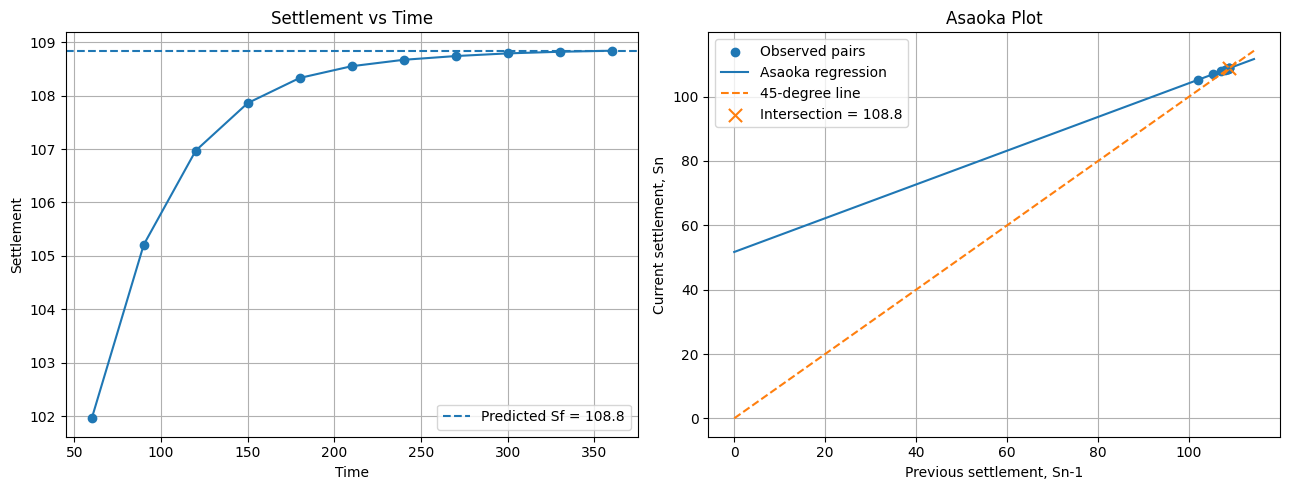

In [22]:
# Yang et al. (2026), Table 4 and Section 4.1, Eq. (1)-(4)
yang_time_days = [30, 60, 90, 120, 150, 180, 210, 240, 270, 300, 330, 360]
yang_settlement_mm = [
    92.84, 101.96, 105.21, 106.97, 107.86, 108.33,
    108.55, 108.67, 108.74, 108.79, 108.82, 108.84
]

# Full Asaoka workflow. start_time=60 retains the Day-60 reading as S_(n-1),
# making the first regression pair (Day 60, Day 90), as described in Section 4.1.
yang_result = analyze_asaoka(
    yang_time_days,
    yang_settlement_mm,
    start_time=60
)

# Published rounded full-series values: beta0=51.715, beta1=0.5248, Sf=108.837 mm.
assert np.isclose(yang_result["delta_t"], 30.0)
assert np.isclose(yang_result["beta0"], 51.715, atol=0.002)
assert np.isclose(yang_result["beta1"], 0.5248, atol=0.0001)
assert np.isclose(yang_result["final_settlement"], 108.837, atol=0.003)

yang_pairs = pd.DataFrame({
    "Pair time (day)": yang_result["pair_time"],
    "S_(n-1) (mm)": yang_result["settlement_previous"],
    "S_n (mm)": yang_result["settlement_current"]
})
display(yang_pairs)

print("Full-series Asaoka validation — Yang et al. (2026)")
print(f"Constant interval       : {yang_result['delta_t']:.1f} days")
print(f"Number of Asaoka pairs  : {len(yang_result['settlement_previous'])}")
print(f"beta0                   : {yang_result['beta0']:.6f} mm (paper: 51.715)")
print(f"beta1                   : {yang_result['beta1']:.6f} (paper: 0.5248)")
print(f"R-squared               : {yang_result['r_squared']:.6f} (diagnostic)")
print(f"Ultimate settlement Sf  : {yang_result['final_settlement']:.4f} mm (paper: ~108.837 mm)")

# Plot both time-settlement and Asaoka regression using the actual published series.
plot_asaoka(yang_result)
plt.show()